# **NAQSH AI**
### Recognising Known Ancient Inscriptions of AlUla with Deep Learning

## Introduction

AlUla is home to thousands of ancient inscriptions written over more than 2,000 years: **Dadanitic** texts of the kingdoms of Dadan and Lihyan, **Nabataean** tomb inscriptions at Hegra, **Minaic**, **Latin**, and **early Islamic Arabic** texts. Visitors can see them carved in rock and stone, but cannot read them. **NAQSH AI** uses Computer Vision to recognise a known inscription from a visitor's photograph and then shows its documented reading and meaning.

## Problem Statement

Reading ancient letters directly (OCR) needs thousands of labelled text images, which do not exist for AlUla. We therefore solve a narrower, honest problem:

> **Given a photograph, can a CNN recognise *which supported inscription* it shows, and reject photos it does not know?**

If recognised, the verified archaeological record is retrieved from a table. The table only *retrieves* information after the CNN has made its visual decision; it is not part of the recognition.

## Dataset

- **181 real photographs**, all taken in AlUla (Wikimedia Commons 117, Flickr 52, Livius.org 10, World History Encyclopedia 2), all under Creative Commons licences.
- **35 supported inscriptions (classes)** with **135 photos**, between 2 and 15 photos each:

| Group | Script | Classes |
|---|---|---|
| Museum objects from Dadan and Umm Daraj | Dadanitic / Lihyanite (one bilingual with Aramaic) | 7 |
| Rock panels at Jabal ʿIkmah | Mainly Dadanitic (not verified per panel) | 8 |
| Tombs and Jabal Ithlib at Hegra | Nabataean | 9 |
| Rock inscriptions around AlUla | Early Islamic Arabic | 7 |
| Single examples | Nabataeo-Arabic, Minaic, Latin, rock art | 4 |

- **46 unknown photos** of *other* AlUla inscriptions, used only to test rejection (never for training).
- **Records** from the OCIANA corpus (Oxford), the Royal Commission for AlUla (RCU) catalogue, and published studies of the Hegra tombs.

## Methodology

**Photo → preprocessing → MobileNetV2 (transfer learning + fine-tuning) → class + confidence → threshold → verified record**

> NAQSH AI recognises **known inscriptions only**. It does **not** perform OCR and cannot read an inscription it was not trained on.

## **1. Import Libraries**

In [1]:
# Data handling
import os
import json
import numpy as np
import pandas as pd

# Images and plots
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Evaluation
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Deep learning
import tensorflow as tf
import keras
from keras import layers

# Fix the random seed so every run gives the same result
keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.18.0
Keras: 3.8.0


## **2. Data Loading and Understanding**

In [2]:
# Read the table of all photos
images = pd.read_csv("metadata/images.csv")

print("Number of photos:", len(images))
images.head()

Number of photos: 181


,image_id,image_path,recognition_label,inscription_id,location,source,source_url,original_image_url,license,author,original_sha1,split
0,IMG-001,dataset/images/IMG-001.jpg,Al-Ḫuraybah 12,Al-Ḫuraybah 12,Al-Ḫuraybah,Livius.org,https://www.livius.org/pictures/saudi-arabia/a...,https://www.livius.org/site/assets/files/65258...,CC0 1.0,Jona Lendering,fa1699a57cc76173adb93ee6a8eb0a50185e56d6,train
1,IMG-002,dataset/images/IMG-002.jpg,Al-Ḫuraybah 12,Al-Ḫuraybah 12,"Dadan sanctuary (al-Khuraybah), al-ʿUlā",Wikimedia Commons,https://commons.wikimedia.org/wiki/File%3ALint...,https://upload.wikimedia.org/wikipedia/commons...,CC BY-SA 4.0,Zunkir,479742c932ef4f816850b3d33a73d415d14617a9,test
2,IMG-003,dataset/images/IMG-003.jpg,Al-Saʿīd 2011.1,Al-Saʿīd 2011.1,Al-Ḫuraybah,Livius.org,https://www.livius.org/pictures/saudi-arabia/a...,https://www.livius.org/site/assets/files/65261...,CC0 1.0,Jona Lendering,562fb9109fbbb6ddb3f0493b77c46c93a52013e2,train
3,IMG-004,dataset/images/IMG-004.jpg,Al-Saʿīd 2011.1,Al-Saʿīd 2011.1,"Dadan sanctuary (al-Khuraybah), al-ʿUlā",Wikimedia Commons,https://commons.wikimedia.org/wiki/File%3AInsc...,https://upload.wikimedia.org/wikipedia/commons...,CC BY-SA 4.0,Zunkir,3c4cf8b2823221c44bbf1b703e90e41222595e1e,test
4,IMG-005,dataset/images/IMG-005.jpg,MUS-UMMDARAJ-PILGRIMAGE,MUS-UMMDARAJ-PILGRIMAGE,"Umm Daraj sanctuary, al-ʿUlā",Livius.org,https://www.livius.org/pictures/saudi-arabia/a...,https://www.livius.org/site/assets/files/65262...,CC0 1.0,Jona Lendering,5d5acb30ded1e824c424256fbdc05ec8539ec55d,train


In [3]:
# Read the verified records (reading and meaning of each inscription)
supported = pd.read_csv("metadata/supported_inscriptions.csv")
supported = supported.fillna("")

supported[["class_name", "name_en", "site", "reading_status"]]

,class_name,name_en,site,reading_status
0,Al-Ḫuraybah 12,Dedication lintel of Ddn (Al-Ḫuraybah 12),"Dadan sanctuary (al-Khuraybah), AlUla",verified transliteration + translation
1,Al-Saʿīd 2011.1,Inscription of King ʿṣy of Dadan,"Dadan sanctuary (al-Khuraybah), AlUla",verified transliteration + translation
2,MUS-DADAN-PRIEST-RELIEF,Camel rider with the word ʾfkl (“priest”),"Dadan sanctuary (al-Khuraybah), AlUla",verified transliteration + translation
3,MUS-DADAN-PILGRIMAGE-LINTEL,Lintel with two pilgrimage inscriptions,"Dadan (al-Khuraybah), AlUla",verified transliteration + translation
4,MUS-UMMDARAJ-EXVOTO-BUST,"Votive torso of Nabbaḥah, priestess of Dhûghâbat","Umm Daraj sanctuary, AlUla",verified transliteration + translation
5,MUS-UMMDARAJ-PILGRIMAGE,Pilgrimage of Hatadiyah and Rfd to Umm Daraj,"Umm Daraj sanctuary, AlUla",translation only (Latin transliteration unavai...
6,JI-P01,Jabal ʿIkmah boulder face P01,"Jabal ʿIkmah, AlUla",no verified reading
7,JI-P02,Jabal ʿIkmah rock panel P02,"Jabal ʿIkmah, AlUla",no verified reading
8,JI-P04,Jabal ʿIkmah rock panel P04,"Jabal ʿIkmah, AlUla",no verified reading
9,JI-P05,Jabal ʿIkmah rock panel P05,"Jabal ʿIkmah, AlUla",no verified reading


In [4]:
# Each inscription needs at least 2 photos: one for training and one for testing
MIN_PHOTOS_PER_CLASS = 2

# Known photos = every photo that is not "unknown"
known = images[images["recognition_label"] != "unknown"]

# Count the photos of each inscription
photo_counts = known["recognition_label"].value_counts()

# Remove inscriptions that have fewer than 2 photos
too_few = photo_counts[photo_counts < MIN_PHOTOS_PER_CLASS].index
images = images[~images["recognition_label"].isin(too_few)]
known = images[images["recognition_label"] != "unknown"]

# The list of inscriptions the model will learn (the classes)
class_names = sorted(known["recognition_label"].unique())

print("Total photos:", len(images))
print("Number of classes:", len(class_names))
print(class_names)

Total photos: 181
Number of classes: 35
['AU-ARABIC-01', 'AU-ARABIC-02', 'AU-ARABIC-03', 'AU-ARABIC-04', 'AU-ARABIC-05', 'AU-ARABIC-06', 'AU-ARABIC-07', 'AU-MINAIC-01', 'AU-NABARAB-01', 'AU-ROCKART-01', 'Al-Saʿīd 2011.1', 'Al-Ḫuraybah 12', 'HG-ITHLIB-01', 'HG-ITHLIB-02', 'HG-ITHLIB-03', 'HG-LATIN-01', 'HG-T021', 'HG-T030', 'HG-T039', 'HG-T044', 'HG-T045', 'HG-T110', 'JI-P01', 'JI-P02', 'JI-P04', 'JI-P05', 'JI-P06', 'JI-P07', 'JI-P08', 'JI-P09', 'MUS-BILINGUAL-DADANITIC-ARAMAIC', 'MUS-DADAN-PILGRIMAGE-LINTEL', 'MUS-DADAN-PRIEST-RELIEF', 'MUS-UMMDARAJ-EXVOTO-BUST', 'MUS-UMMDARAJ-PILGRIMAGE']


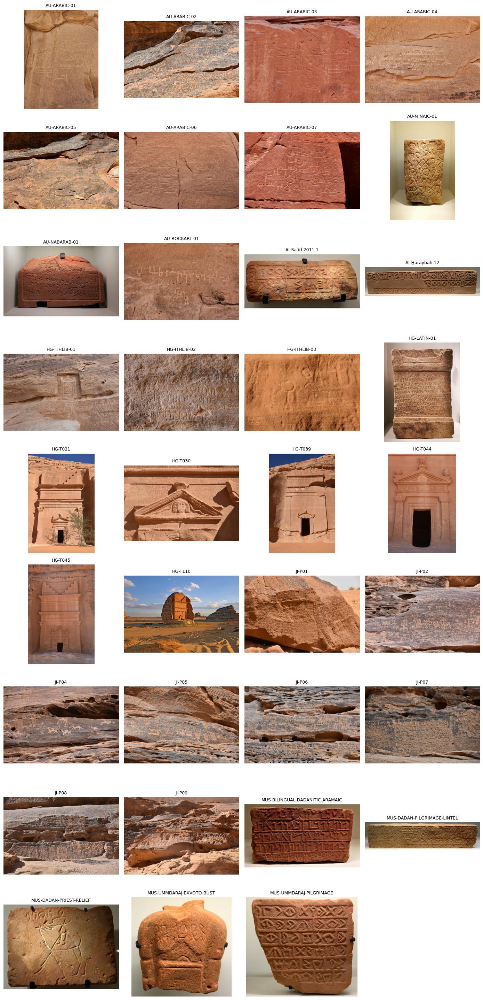

In [5]:
# Show one photo of each inscription
n_cols = 4
n_rows = int(np.ceil(len(class_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for i in range(len(class_names)):
    label = class_names[i]
    path = known[known["recognition_label"] == label]["image_path"].iloc[0]
    image = ImageOps.exif_transpose(Image.open(path))
    axes[i].imshow(image)
    axes[i].set_title(label, fontsize=9)

plt.tight_layout()
plt.show()

In [6]:
# Read the bigger table of documented AlUla inscriptions (text only, no photos)
knowledge_base = pd.read_csv("metadata/knowledge_base.csv")

print("Documented inscriptions:", len(knowledge_base))
print("Inscriptions with photos:", len(supported))

Documented inscriptions: 1657
Inscriptions with photos: 35


**Images vs. archaeological records**
- A **photo** is what the CNN sees. It only learns *which object or panel* is in the picture.
- A **record** holds the scholarly knowledge: the *transliteration* (ancient letters written in Latin script) and the *translation* (the meaning).
- We have **1,657 text records** but photos of only **35 inscriptions**. A record without photos cannot be recognised, so 1,657 records are **not** 1,657 labelled images.

## **3. Exploratory Data Analysis**

In [7]:
# Count the photos of each inscription in each split
counts = pd.crosstab(images["recognition_label"], images["split"])
counts

split,test,test_unknown,train,val,val_unknown
recognition_label,,,,,
AU-ARABIC-01,1,0,3,0,0
AU-ARABIC-02,1,0,5,0,0
AU-ARABIC-03,1,0,1,0,0
AU-ARABIC-04,1,0,1,0,0
AU-ARABIC-05,1,0,2,0,0
AU-ARABIC-06,1,0,2,0,0
AU-ARABIC-07,1,0,3,0,0
AU-MINAIC-01,1,0,1,0,0
AU-NABARAB-01,1,0,1,0,0


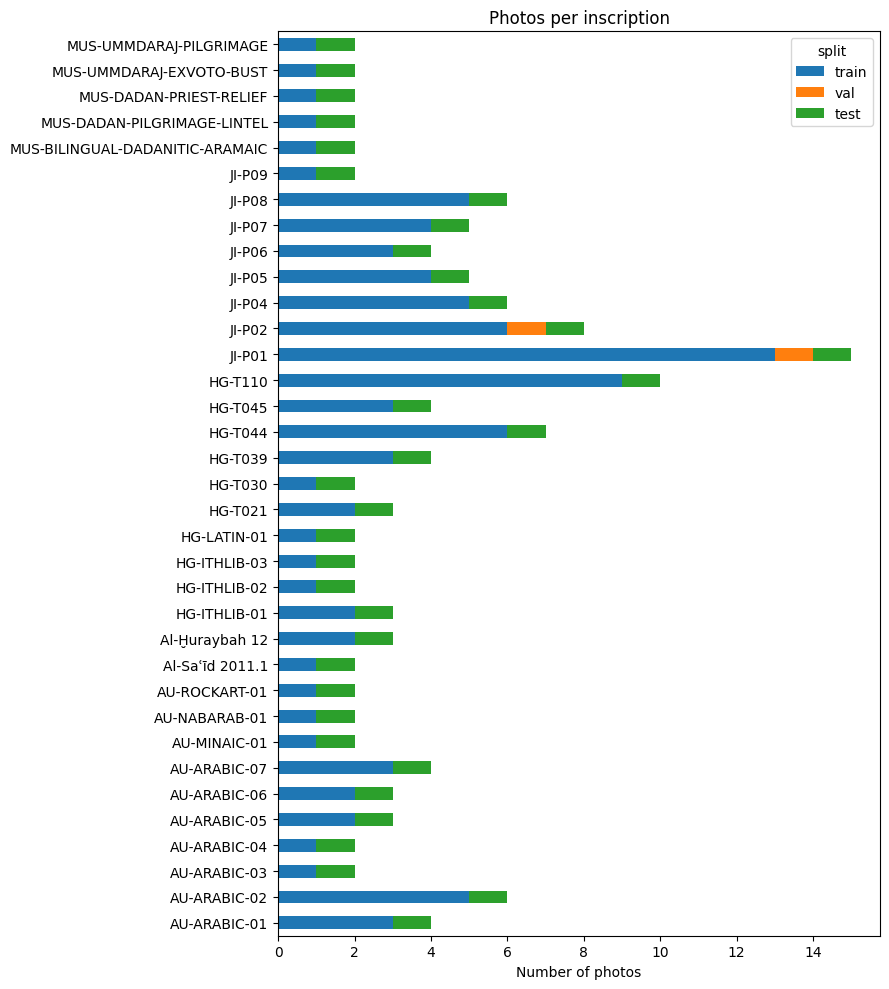

In [8]:
# Bar chart: number of photos per inscription
class_counts = counts.loc[class_names, ["train", "val", "test"]]

class_counts.plot(kind="barh", stacked=True, figsize=(9, 10))
plt.title("Photos per inscription")
plt.xlabel("Number of photos")
plt.ylabel("")
plt.tight_layout()
plt.show()

**What the table and chart show**
- Every class keeps **exactly 1 test photo**; all its other photos are used for training.
- The data is **small and imbalanced**: most classes have only **1–3 training photos**, while a few have many (JI-P01 has 13, HG-T110 has 9). The model may prefer the classes it has seen more often.
- Only **2 known photos** (JI-P01 and JI-P02) are in validation, because almost every photo is needed for training or testing.

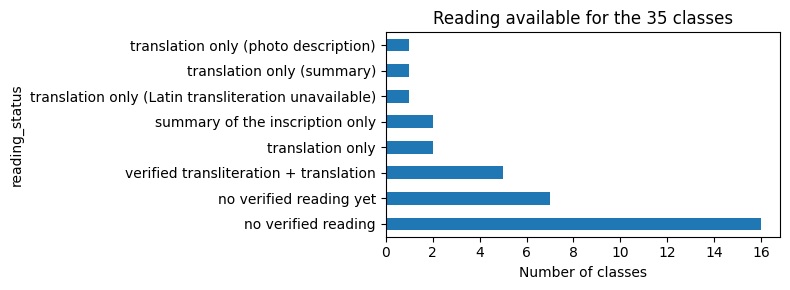

In [9]:
# Bar chart: what kind of reading each inscription has
supported["reading_status"].value_counts().plot(kind="barh", figsize=(8, 3))
plt.title(f"Reading available for the {len(class_names)} classes")
plt.xlabel("Number of classes")
plt.tight_layout()
plt.show()

       width  height
count  181.0   181.0
mean   607.0   462.0
std     74.0    97.0
min    360.0   148.0
25%    640.0   427.0
50%    640.0   427.0
75%    640.0   480.0
max    640.0   640.0


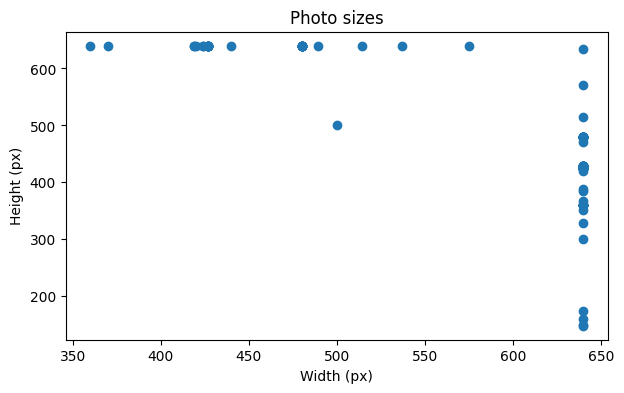

In [10]:
# Read the width and height of every photo
widths = []
heights = []
for path in images["image_path"]:
    w, h = Image.open(path).size
    widths.append(w)
    heights.append(h)

images["width"] = widths
images["height"] = heights
print(images[["width", "height"]].describe().round(0))

plt.figure(figsize=(7, 4))
plt.scatter(widths, heights)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Photo sizes")
plt.show()

**Photo sizes:** most photos are **640 × 427 px** (the longest side was limited to 640 px), but heights go from 148 px to 640 px (wide lintels, tall statues). We **pad** every photo to a 224 × 224 square with grey instead of stretching it, so the shape of the letters is not distorted.

In [11]:
# Check for empty cells in the table
print("Missing values:", images.isna().sum().sum())

# Check that every image file opens
bad_files = []
for path in images["image_path"]:
    try:
        Image.open(path).verify()
    except Exception:
        bad_files.append(path)

print("Broken image files:", len(bad_files))

Missing values: 29
Broken image files: 0


In [12]:
# 1) Exact duplicates: two photos from the same original file
print("Exact duplicates:", images["original_sha1"].duplicated().sum())

# 2) Near-duplicates: shrink each photo to 8x8 and compare the patterns
def average_hash(path):
    small = Image.open(path).convert("L").resize((8, 8))
    small = np.array(small)
    return small > small.mean()      # 64 True/False values

ids = list(images["image_id"])
paths = list(images["image_path"])
labels = list(images["recognition_label"])
hashes = [average_hash(p) for p in paths]

near_duplicates = []
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        distance = (hashes[i] != hashes[j]).sum()   # how many of the 64 values differ
        if distance <= 6:
            near_duplicates.append([ids[i], ids[j], labels[i], labels[j], distance])

pd.DataFrame(near_duplicates, columns=["photo A", "photo B", "label A", "label B", "distance"])

Exact duplicates: 0


,photo A,photo B,label A,label B,distance
0,IMG-001,IMG-007,Al-Ḫuraybah 12,MUS-DADAN-PILGRIMAGE-LINTEL,4
1,IMG-001,IMG-117,Al-Ḫuraybah 12,HG-LATIN-01,6
2,IMG-003,IMG-048,Al-Saʿīd 2011.1,JI-P01,5
3,IMG-003,IMG-172,Al-Saʿīd 2011.1,unknown,4
4,IMG-008,IMG-182,MUS-DADAN-PILGRIMAGE-LINTEL,unknown,6
5,IMG-013,IMG-014,JI-P01,JI-P01,6
6,IMG-035,IMG-088,JI-P01,AU-NABARAB-01,2
7,IMG-035,IMG-138,JI-P01,HG-T110,4
8,IMG-048,IMG-060,JI-P01,JI-P01,6
9,IMG-056,IMG-181,JI-P07,unknown,6


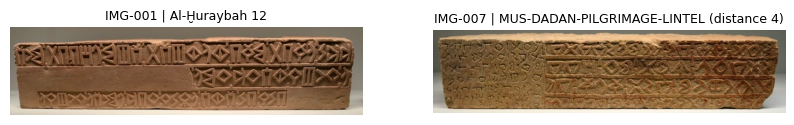

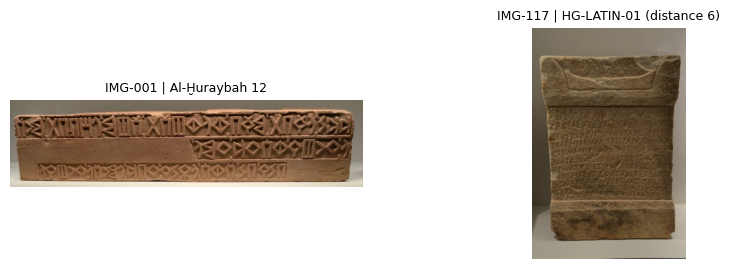

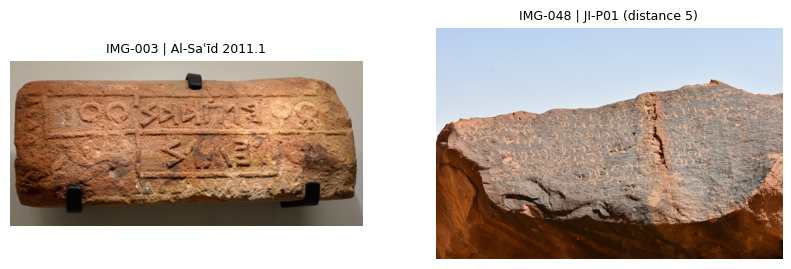

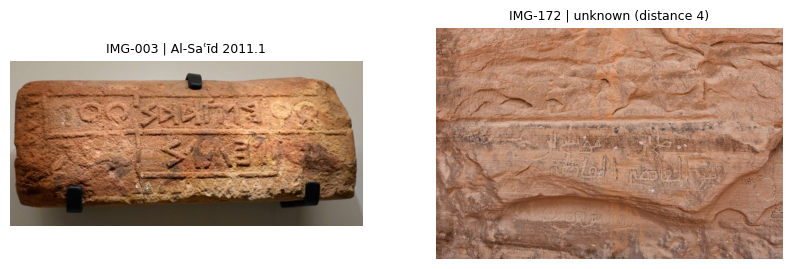

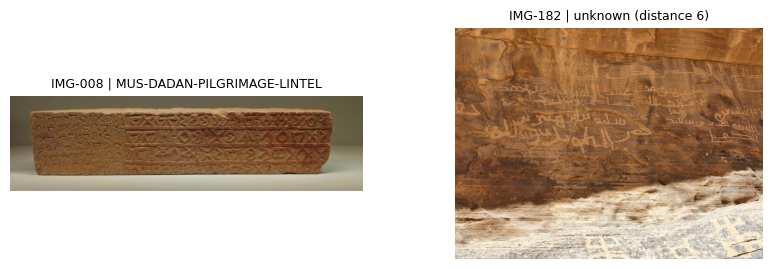

...

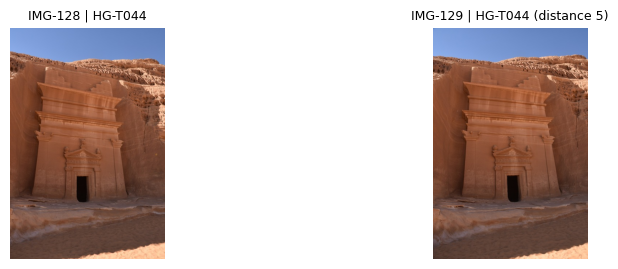

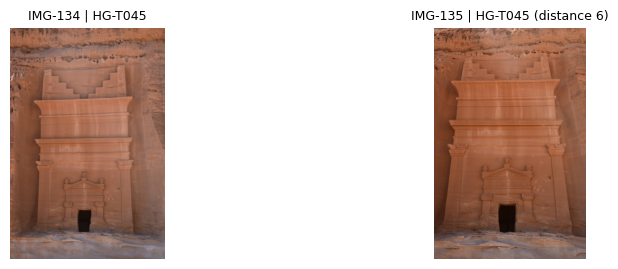

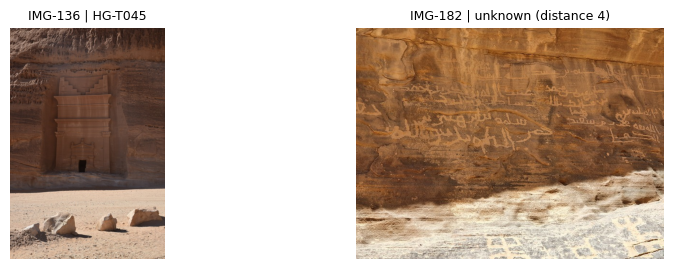

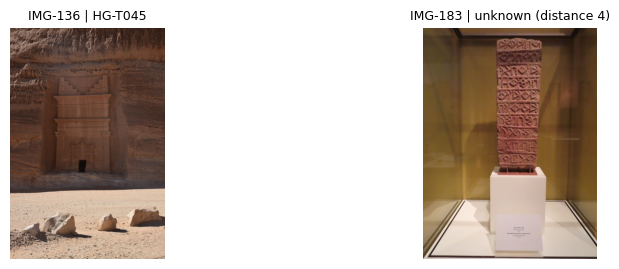

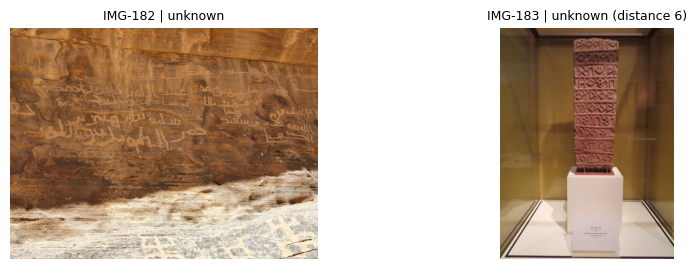

In [13]:
# Show every flagged pair side by side
path_of = dict(zip(ids, paths))

for a, b, label_a, label_b, distance in near_duplicates:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].imshow(Image.open(path_of[a]))
    axes[0].set_title(f"{a} | {label_a}", fontsize=9)
    axes[1].imshow(Image.open(path_of[b]))
    axes[1].set_title(f"{b} | {label_b} (distance {distance})", fontsize=9)
    axes[0].axis("off")
    axes[1].axis("off")
    plt.show()

**What the quality checks found**
- **No broken files and no exact duplicates.**
- **29 missing values**: they are all in the `original_image_url` column of the 29 photos added by our team. This column is only documentation, so training is not affected.
- The 8×8 hash flagged **21 similar pairs**. The hash is very coarse: most pairs are **different inscriptions with a similar overall look** (for example a long lintel on a grey background), so no labels change.
- **Pairs worth a closer look:**
  - **IMG-076 (train) and IMG-078 (test)** are two photos of the same inscription, AU-ARABIC-02. If they are almost the same shot, the test of this class is too easy (the model gave IMG-078 a score of 1.000).
  - Several **unknown photos look like training photos** (IMG-172, IMG-175, IMG-181, IMG-182, IMG-183). They were checked by eye as other inscriptions. All test unknown photos were still rejected in section 8.

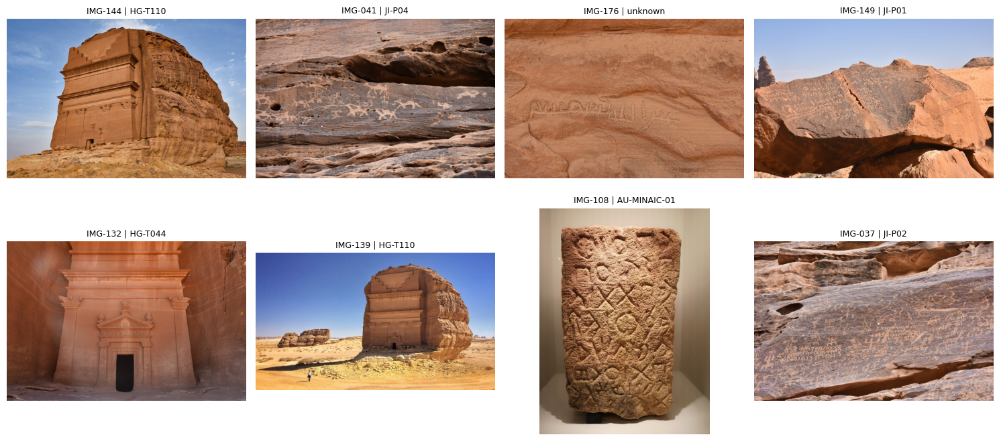

In [14]:
# Show 8 random photos (known and unknown)
sample = images.sample(8, random_state=7)
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.ravel()

for i in range(8):
    row = sample.iloc[i]
    axes[i].imshow(Image.open(row["image_path"]))
    axes[i].set_title(f"{row['image_id']} | {row['recognition_label']}", fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## **4. Data Preprocessing**

### 4.1 Train / Validation / Test Split

In [15]:
# Read the saved split
train = pd.read_csv("dataset/splits/train.csv")
val = pd.read_csv("dataset/splits/val.csv")
test = pd.read_csv("dataset/splits/test.csv")

# Remove inscriptions that have too few photos (same as section 2)
train = train[~train["recognition_label"].isin(too_few)].reset_index(drop=True)
val = val[~val["recognition_label"].isin(too_few)].reset_index(drop=True)
test = test[~test["recognition_label"].isin(too_few)].reset_index(drop=True)

# ---- Leakage checks: the program stops with an error if one fails ----
all_ids = pd.concat([train, val, test])["image_id"]
assert not all_ids.duplicated().any(), "a photo is in two splits"
assert set(all_ids) == set(images["image_id"]), "a photo is missing from the splits"

train_files = set(images[images["image_id"].isin(train["image_id"])]["original_sha1"])
test_files = set(images[images["image_id"].isin(test["image_id"])]["original_sha1"])
assert len(train_files & test_files) == 0, "the same file is in train and test"

assert "unknown" not in set(train["recognition_label"]), "unknown photos must not be in train"
assert set(train["recognition_label"]) == set(class_names), "a class has no training photo"

test_known_labels = set(test["recognition_label"]) - {"unknown"}
assert test_known_labels == set(class_names), "a class has no test photo"

# ---- Print the size of each split ----
def count(df):
    n_unknown = (df["recognition_label"] == "unknown").sum()
    return f"{len(df) - n_unknown} known + {n_unknown} unknown"

print("Train:     ", count(train))
print("Validation:", count(val))
print("Test:      ", count(test))
print("No leakage found.")

Train:      98 known + 0 unknown
Validation: 2 known + 23 unknown
Test:       35 known + 23 unknown
No leakage found.


**Result: no leakage found.**
- **Train:** 98 known photos (no unknown photos, because the model must never learn "unknown" as a class).
- **Validation:** 2 known + 23 unknown photos. The unknown photos are used to choose the threshold.
- **Test:** 35 known photos (exactly one per class) + 23 unknown photos.
- Every photo is in **one** split only, and no original file appears in both train and test.
- Augmentation is applied **only to training photos, on the fly**. Augmented images are never saved and never used for testing.

### 4.2 Encode Labels

In [16]:
# Give each class a number: the first class is 0, the next is 1, ...
class_to_id = {}
for i, label in enumerate(class_names):
    class_to_id[label] = i

class_to_id

{'AU-ARABIC-01': 0,
 'AU-ARABIC-02': 1,
 'AU-ARABIC-03': 2,
 'AU-ARABIC-04': 3,
 'AU-ARABIC-05': 4,
 'AU-ARABIC-06': 5,
 'AU-ARABIC-07': 6,
 'AU-MINAIC-01': 7,
 'AU-NABARAB-01': 8,
 'AU-ROCKART-01': 9,
 'Al-Saʿīd 2011.1': 10,
 'Al-Ḫuraybah 12': 11,
 'HG-ITHLIB-01': 12,
 'HG-ITHLIB-02': 13,
 'HG-ITHLIB-03': 14,
 'HG-LATIN-01': 15,
 'HG-T021': 16,
 'HG-T030': 17,
 'HG-T039': 18,
 'HG-T044': 19,
 'HG-T045': 20,
 'HG-T110': 21,
 'JI-P01': 22,
 'JI-P02': 23,
 'JI-P04': 24,
 'JI-P05': 25,
 'JI-P06': 26,
 'JI-P07': 27,
 'JI-P08': 28,
 'JI-P09': 29,
 'MUS-BILINGUAL-DADANITIC-ARAMAIC': 30,
 'MUS-DADAN-PILGRIMAGE-LINTEL': 31,
 'MUS-DADAN-PRIEST-RELIEF': 32,
 'MUS-UMMDARAJ-EXVOTO-BUST': 33,
 'MUS-UMMDARAJ-PILGRIMAGE': 34}

### 4.3 Resize and Normalize

In [17]:
IMG_SIZE = 224

# Open a photo, fix its rotation, and pad it with grey to 224x224 (no stretching)
def load_image(path):
    image = Image.open(path)
    image = ImageOps.exif_transpose(image)
    image = image.convert("RGB")
    image = ImageOps.pad(image, (IMG_SIZE, IMG_SIZE), color=(127, 127, 127))
    return np.array(image, dtype="float32")

# Load the photos (X) and their class numbers (y) of a table. Unknown = -1
def load_split(df):
    X = []
    y = []
    for _, row in df.iterrows():
        X.append(load_image(row["image_path"]))
        y.append(class_to_id.get(row["recognition_label"], -1))
    return np.array(X), np.array(y)

# Split each table into known and unknown photos
val_known = val[val["recognition_label"] != "unknown"]
val_unknown = val[val["recognition_label"] == "unknown"]
test_known = test[test["recognition_label"] != "unknown"].reset_index(drop=True)
test_unknown = test[test["recognition_label"] == "unknown"].reset_index(drop=True)

X_train, y_train = load_split(train)
X_val, y_val = load_split(val_known)
X_test, y_test = load_split(test_known)
X_val_unknown, _ = load_split(val_unknown)
X_test_unknown, _ = load_split(test_unknown)

print("Train:", X_train.shape)
print("Val:", X_val.shape, "| Test:", X_test.shape)
print("Unknown val:", X_val_unknown.shape, "| Unknown test:", X_test_unknown.shape)

Train: (98, 224, 224, 3)
Val: (2, 224, 224, 3) | Test: (35, 224, 224, 3)
Unknown val: (23, 224, 224, 3) | Unknown test: (23, 224, 224, 3)


In [18]:
# MobileNetV2 needs pixel values between -1 and 1 (they are 0 to 255 now)
preprocess = keras.applications.mobilenet_v2.preprocess_input

example = preprocess(X_train[:1].copy())
print("Before:", X_train.min(), "to", X_train.max())
print("After: ", example.min(), "to", example.max())

Before: 0.0 to 255.0
After:  -1.0 to 0.9764706


### 4.4 Training-Only Augmentation

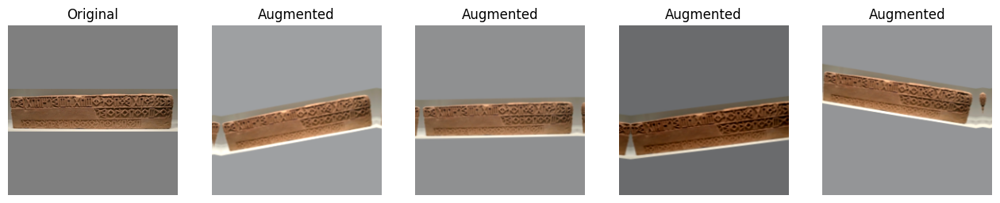

In [19]:
# Small random changes to the training photos.
# No flipping: a mirrored inscription is a different text.
augment = keras.Sequential([
    layers.RandomRotation(0.04),                        # rotate a little
    layers.RandomZoom((-0.25, 0.1)),                    # zoom in or out
    layers.RandomTranslation(0.1, 0.1),                 # move left/right/up/down
    layers.RandomBrightness(0.2, value_range=(0, 255)), # lighter or darker
    layers.RandomContrast(0.3),                         # more or less contrast
])

# Show one photo and 4 changed versions of it
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(X_train[0].astype("uint8"))
axes[0].set_title("Original")

for i in range(1, 5):
    changed = augment(X_train[:1], training=True)[0].numpy()
    axes[i].imshow(np.clip(changed, 0, 255).astype("uint8"))
    axes[i].set_title("Augmented")

for ax in axes:
    ax.axis("off")
plt.show()

### 4.5 TensorFlow Dataset

In [20]:
REPEATS = 40      # each training photo is shown 40 times per epoch
BATCH_SIZE = 16

# Augment a batch of photos, then scale it to -1..1
def prepare_batch(x, y):
    x = augment(x, training=True)
    x = preprocess(x)
    return x, y

# Build the training data: repeat -> shuffle -> batches -> augment
def make_train_dataset(X, y):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    ds = ds.repeat(REPEATS)
    ds = ds.shuffle(1000, seed=42)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(prepare_batch)
    return ds

train_ds = make_train_dataset(X_train, y_train)
val_data = (preprocess(X_val.copy()), y_val)

print("Training samples per epoch:", len(X_train) * REPEATS, "made from", len(X_train), "real photos")

Training samples per epoch: 3920 made from 98 real photos


## **5. Model Building**

In [21]:
# Build the model: MobileNetV2 (pretrained) + a new output layer
def build_model():
    # MobileNetV2 trained on ImageNet, without its last layer
    backbone = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
        pooling="avg",
    )
    backbone.trainable = False   # freeze it for now

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = backbone(inputs, training=False)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(class_names), activation="softmax")(x)   # one output per inscription

    model = keras.Model(inputs, outputs)
    return model, backbone

model, backbone = build_model()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 35)             │        44,835 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,302,819 (8.78 MB)

 Trainable params: 44,835 (175.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**The model**
- **MobileNetV2** was pretrained on 1.2 million ImageNet photos. It already detects edges, textures and shapes, so it can learn from very few photos, and it is light enough for a laptop CPU.
- We remove its ImageNet output layer and add **Dropout (0.3)** and a **Dense softmax layer with 35 outputs**, one per inscription.
- In stage 1 only the new layer learns: **44,835 trainable parameters** out of 2.3 million. The other 2,257,984 are frozen.
- `training=False` keeps the BatchNormalization statistics fixed, which matters with tiny data.

## **6. Model Training**

### 6.1 Stage 1: Train the Classification Head

In [22]:
os.makedirs("models", exist_ok=True)

# Save the best model, and stop if validation loss does not improve for 3 epochs
checkpoint = keras.callbacks.ModelCheckpoint("models/naqsh_model.keras", monitor="val_loss", save_best_only=True)
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

# Stage 1: train only the new output layer
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_head = model.fit(
    train_ds,
    validation_data=val_data,
    epochs=10,
    callbacks=[checkpoint, early_stop],
    verbose=2,
)

Epoch 1/10
245/245 - 86s - 353ms/step - accuracy: 0.8291 - loss: 0.7296 - val_accuracy: 1.0000 - val_loss: 0.4394
Epoch 2/10
245/245 - 80s - 328ms/step - accuracy: 0.9939 - loss: 0.0688 - val_accuracy: 1.0000 - val_loss: 0.3435
Epoch 3/10
245/245 - 72s - 294ms/step - accuracy: 0.9977 - loss: 0.0329 - val_accuracy: 1.0000 - val_loss: 0.1314
Epoch 4/10
245/245 - 76s - 310ms/step - accuracy: 0.9980 - loss: 0.0213 - val_accuracy: 1.0000 - val_loss: 0.1526
Epoch 5/10
245/245 - 69s - 282ms/step - accuracy: 0.9997 - loss: 0.0139 - val_accuracy: 1.0000 - val_loss: 0.1913
Epoch 6/10
245/245 - 67s - 272ms/step - accuracy: 0.9987 - loss: 0.0111 - val_accuracy: 1.0000 - val_loss: 0.1723


### 6.2 Stage 2: Fine-Tune MobileNetV2

In [23]:
# Unfreeze the last 30 layers of MobileNetV2 (BatchNormalization layers stay frozen)
def unfreeze_last_layers(backbone):
    backbone.trainable = True
    for layer in backbone.layers[:-30]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

unfreeze_last_layers(backbone)

# Stage 2: train again with a much smaller learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds,
    validation_data=val_data,
    epochs=10,
    callbacks=[checkpoint, early_stop],
    verbose=2,
)

Epoch 1/10
245/245 - 75s - 306ms/step - accuracy: 0.9977 - loss: 0.0114 - val_accuracy: 1.0000 - val_loss: 0.0582
Epoch 2/10
245/245 - 73s - 297ms/step - accuracy: 0.9992 - loss: 0.0047 - val_accuracy: 1.0000 - val_loss: 0.0107
Epoch 3/10
245/245 - 71s - 291ms/step - accuracy: 0.9982 - loss: 0.0051 - val_accuracy: 1.0000 - val_loss: 0.3628
Epoch 4/10
245/245 - 71s - 289ms/step - accuracy: 0.9990 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 0.0136
Epoch 5/10
245/245 - 70s - 285ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 0.0407


**What happened during training**
- **Stage 1:** training accuracy jumped from **0.83 to 0.99** after the first epochs. The best validation loss was at epoch 3 (**0.131**), and early stopping ended the stage at epoch 6.
- **Stage 2 (fine-tuning):** validation loss fell to **0.011** at epoch 2; early stopping ended the stage at epoch 5 and kept the best weights.
- Each epoch took about **70–85 seconds** on a laptop CPU (3,920 augmented samples per epoch).

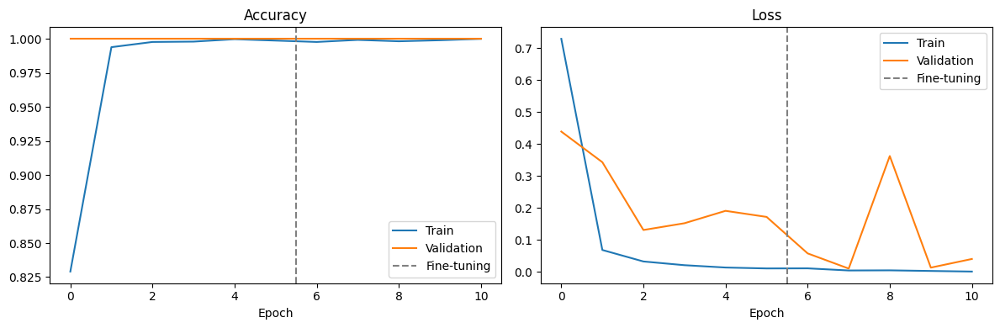

Final train accuracy: 1.0 | train loss: 0.0013
Final validation accuracy: 1.0 | validation loss: 0.0407


In [24]:
# Join the history of both stages
train_acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]
train_loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]

# Where stage 2 starts on the plot
fine_start = len(history_head.history["loss"]) - 0.5

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_acc, label="Train")
plt.plot(val_acc, label="Validation")
plt.axvline(fine_start, color="grey", linestyle="--", label="Fine-tuning")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss, label="Train")
plt.plot(val_loss, label="Validation")
plt.axvline(fine_start, color="grey", linestyle="--", label="Fine-tuning")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

print("Final train accuracy:", round(train_acc[-1], 3), "| train loss:", round(train_loss[-1], 4))
print("Final validation accuracy:", round(val_acc[-1], 3), "| validation loss:", round(val_loss[-1], 4))

**How to read the curves**
- Training accuracy reaches **1.00** and training loss drops to **0.001**. With so few photos, the model fits the training set easily, so this shows that **training works**, not that the model generalises.
- Validation accuracy is **1.00 in every epoch** because there are only **2 known validation photos**. This is a weak signal: early stopping is a safety net here, not a tuning tool.
- The real measure of the model is the **test set** in the next section.

In [27]:
# Load the best saved model and save the list of class names next to it
model = keras.models.load_model("models/naqsh_model.keras")

with open("models/class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=1)

print("Model loaded from models/naqsh_model.keras")

Model loaded from models/naqsh_model.keras


## **7. Model Evaluation**

In [28]:
# Predict the test photos (photos the model never saw)
test_probs = model.predict(preprocess(X_test.copy()), verbose=0)   # a score for every class
test_pred = test_probs.argmax(axis=1)                              # the class with the highest score

val_probs = model.predict(preprocess(X_val.copy()), verbose=0)
val_pred = val_probs.argmax(axis=1)

n_test_correct = (test_pred == y_test).sum()
n_val_correct = (val_pred == y_val).sum()

print("Test photos:", len(y_test))
print(f"Validation accuracy: {accuracy_score(y_val, val_pred):.3f}  ({n_val_correct}/{len(y_val)})")
print(f"Test accuracy:       {accuracy_score(y_test, test_pred):.3f}  ({n_test_correct}/{len(y_test)})")
print(f"Test macro-F1:       {f1_score(y_test, test_pred, average='macro'):.3f}")

Test photos: 35
Validation accuracy: 1.000  (2/2)
Test accuracy:       0.743  (26/35)
Test macro-F1:       0.686


**Main result:** the model recognised **26 of the 35 test photos (74.3 %)**. Each test photo is a real photograph the model never saw during training. A random guess among 35 classes would be right only about **3 %** of the time.

The macro-F1 (**0.686**) is lower than the accuracy because, when the model confuses two classes, both of them lose: the true class gets a missed photo, and the predicted class gets a wrong one.

In [29]:
# Precision, recall and F1 for each class
all_classes = list(range(len(class_names)))
print(classification_report(y_test, test_pred, labels=all_classes, target_names=class_names, zero_division=0))

                                 precision    recall  f1-score   support

                   AU-ARABIC-01       0.00      0.00      0.00         1
                   AU-ARABIC-02       0.50      1.00      0.67         1
                   AU-ARABIC-03       1.00      1.00      1.00         1
                   AU-ARABIC-04       1.00      1.00      1.00         1
                   AU-ARABIC-05       0.00      0.00      0.00         1
                   AU-ARABIC-06       0.00      0.00      0.00         1
                   AU-ARABIC-07       0.00      0.00      0.00         1
                   AU-MINAIC-01       1.00      1.00      1.00         1
                  AU-NABARAB-01       1.00      1.00      1.00         1
                  AU-ROCKART-01       1.00      1.00      1.00         1
                Al-Saʿīd 2011.1       0.00      0.00      0.00         1
                 Al-Ḫuraybah 12       1.00      1.00      1.00         1
                   HG-ITHLIB-01       1.00      1.

With **one test photo per class**, each recall is either 0 or 1, so read the report as *which classes were recognised*:
- **Recognised (26):** all 6 Dadan and Umm Daraj museum pieces except Al-Saʿīd 2011.1, the bilingual block, the Minaic, Latin and Nabataeo-Arabic inscriptions, the rock art, all 3 Jabal Ithlib inscriptions, 4 of the 6 Hegra tombs, 6 of the 8 Jabal ʿIkmah panels, and 3 of the 7 Arabic panels.
- **A precision of 0.50** (for example HG-T044, HG-T110, JI-P01, JI-P07, AU-ARABIC-02) means the class got its own photo **and** a photo of another class.

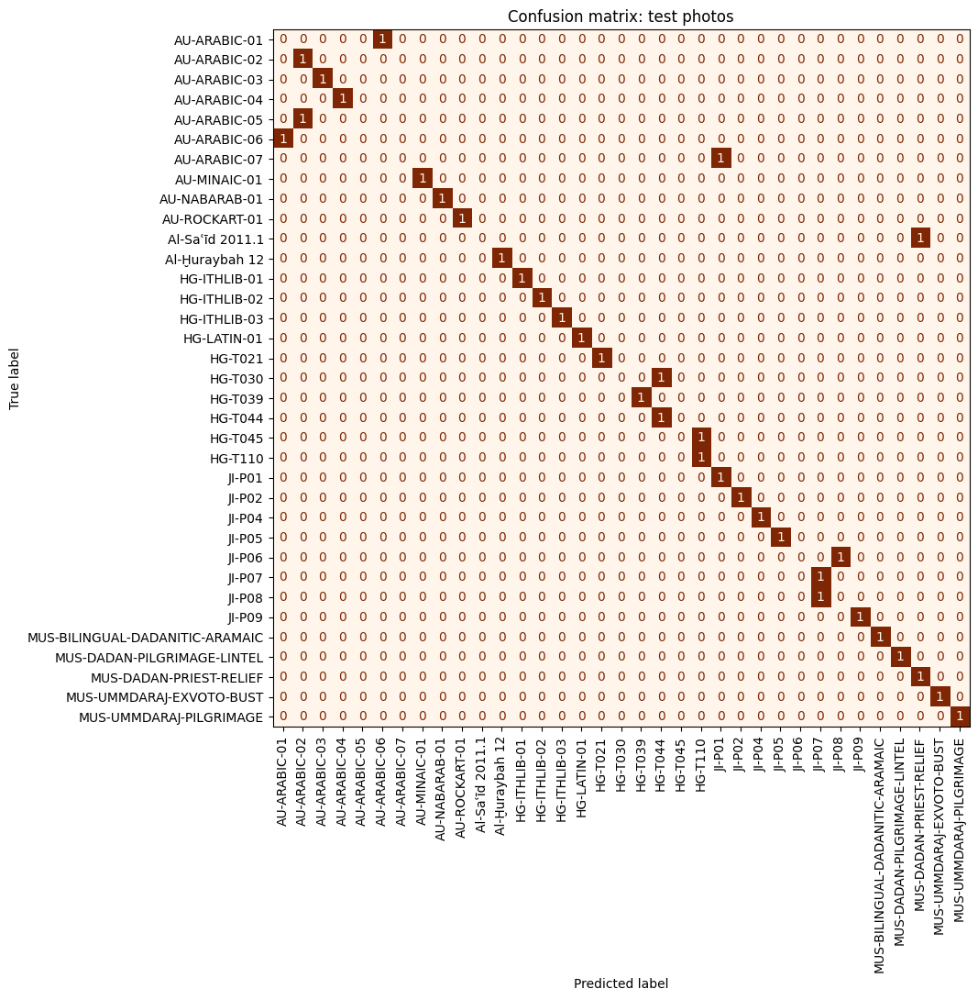

In [30]:
# Confusion matrix: rows = true class, columns = predicted class
fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    labels=all_classes,
    display_labels=class_names,
    xticks_rotation=90,
    cmap="Oranges",
    colorbar=False,
    ax=ax,
)
plt.title("Confusion matrix: test photos")
plt.tight_layout()
plt.show()

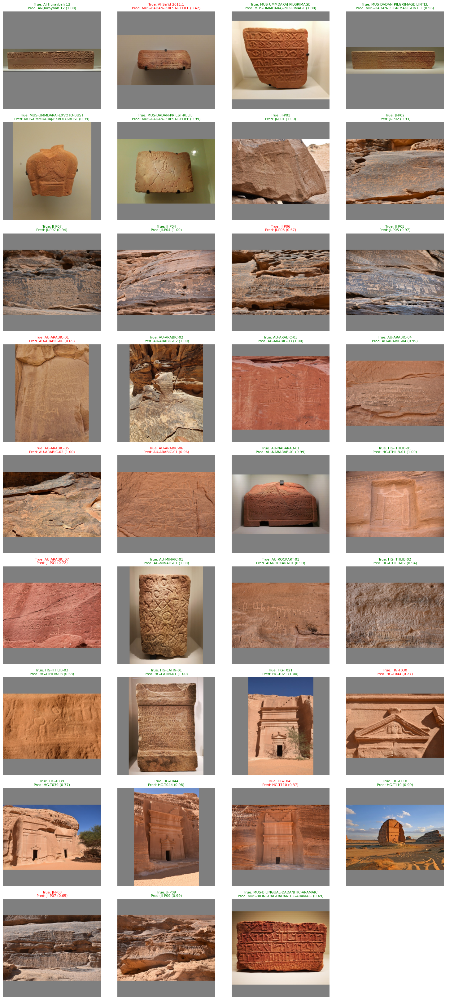

In [31]:
# Show every test photo: green title = correct, red title = wrong
n_cols = 4
n_rows = int(np.ceil(len(X_test) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for i in range(len(X_test)):
    true_name = class_names[y_test[i]]
    pred_name = class_names[test_pred[i]]
    score = test_probs[i].max()

    if test_pred[i] == y_test[i]:
        color = "green"
    else:
        color = "red"

    axes[i].imshow(X_test[i].astype("uint8"))
    axes[i].set_title(f"True: {true_name}\nPred: {pred_name} ({score:.2f})", fontsize=8, color=color)

plt.tight_layout()
plt.show()

**Where the 9 mistakes happened**

| True inscription | Predicted as | What they have in common |
|---|---|---|
| AU-ARABIC-01 | AU-ARABIC-06 | Early Arabic panels from AlUla |
| AU-ARABIC-06 | AU-ARABIC-01 | The same pair, in the other direction |
| AU-ARABIC-05 | AU-ARABIC-02 | Early Arabic panels from AlUla |
| AU-ARABIC-07 | JI-P01 | Text carved on a rock face; only 3 training photos |
| HG-T030 | HG-T044 | Two Nabataean tomb façades at Hegra |
| HG-T045 | HG-T110 | Two Nabataean tomb façades at Hegra |
| JI-P06 | JI-P08 | Two panels on the same mountain |
| JI-P08 | JI-P07 | Two panels on the same mountain |
| Al-Saʿīd 2011.1 | MUS-DADAN-PRIEST-RELIEF | Two sandstone blocks from the same Dadan sanctuary |

**Every mistake is between inscriptions that look alike**: the same script, the same site, and the same kind of stone. The model never confused, for example, a Hegra tomb with a museum object. 8 of these 9 classes have only **1–3 training photos**, so more photos of these inscriptions should help the most.

### 7.1 Second Check: Swap Training and Test Photos
The test set has one photo per class, which is very few. We train a **fresh model** where each class's test photo becomes a training photo and one of its training photos becomes the test photo. This gives **one more independent test prediction per class**.

In [32]:
# For every class: its test photo goes to training, and its first training photo becomes the test photo
swap_train_parts = []
swap_test_parts = []
for c in class_names:
    class_train = train[train["recognition_label"] == c]
    class_test = test_known[test_known["recognition_label"] == c]

    swap_test_parts.append(class_train.iloc[:1])      # first training photo -> test
    swap_train_parts.append(class_test)               # test photo -> train
    swap_train_parts.append(class_train.iloc[1:])     # other training photos stay in train

swap_train = pd.concat(swap_train_parts)
swap_test = pd.concat(swap_test_parts)

X_swap_train, y_swap_train = load_split(swap_train)
X_swap_test, y_swap_test = load_split(swap_test)

# Train a new model with the same recipe (fixed 8 + 8 epochs)
keras.utils.set_random_seed(42)
swap_model, swap_backbone = build_model()
swap_ds = make_train_dataset(X_swap_train, y_swap_train)

# Stage 1
swap_model.compile(optimizer=keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
swap_model.fit(swap_ds, epochs=8, verbose=0)

# Stage 2
unfreeze_last_layers(swap_backbone)
swap_model.compile(optimizer=keras.optimizers.Adam(0.00001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
swap_model.fit(swap_ds, epochs=8, verbose=0)

# Test the new model
swap_pred = swap_model.predict(preprocess(X_swap_test.copy()), verbose=0).argmax(axis=1)
n_swap_correct = (swap_pred == y_swap_test).sum()

print(f"Swapped-split accuracy: {n_swap_correct / len(y_swap_test):.3f}  ({n_swap_correct}/{len(y_swap_test)})")
print(f"Both runs together: {n_test_correct + n_swap_correct}/{len(y_test) + len(y_swap_test)} test photos correct")

Swapped-split accuracy: 0.800  (28/35)
Both runs together: 54/70 test photos correct


**Second check:** the fresh model with swapped photos recognised **28 of 35 (80.0 %)**. Together, the two runs got **54 of 70 independent test photos (77 %)** right.

The two results are close (74 % and 80 %), so the first result was **not just luck** in choosing the test photos.

## **8. Unknown Inscription Recognition**
A softmax classifier always picks one of its supported classes, even for an inscription it has never seen. We accept a prediction only if its **highest softmax score** is above a threshold.
- The threshold is chosen on the **validation** unknown photos, so that 95 % of them are rejected. The test set is **not** used to choose it.
- Softmax scores are **not calibrated probabilities**; we use them only as a ranking score.

In [33]:
# Highest score of each unknown validation photo
val_unknown_probs = model.predict(preprocess(X_val_unknown.copy()), verbose=0)
val_unknown_scores = val_unknown_probs.max(axis=1)

# Threshold = the score that is higher than 95% of unknown photos
threshold = float(np.percentile(val_unknown_scores, 95))

with open("models/threshold.json", "w") as f:
    json.dump({"threshold": threshold}, f)

print(f"Threshold: {threshold:.3f}")
print("Unknown validation photos rejected:", (val_unknown_scores < threshold).sum(), "/", len(val_unknown_scores))

Threshold: 0.997
Unknown validation photos rejected: 21 / 23


**The threshold is 0.997.** Unknown inscriptions can still get very high scores, so to reject 95 % of the validation unknown photos (21 of 23), the bar has to be very high.

In [34]:
# Highest score of each test photo
test_known_scores = test_probs.max(axis=1)
test_unknown_scores = model.predict(preprocess(X_test_unknown.copy()), verbose=0).max(axis=1)

# A known photo is accepted if its score reaches the threshold
accepted = test_known_scores >= threshold
correct = test_pred == y_test

correctly_accepted = (accepted & correct).sum()          # accepted with the right class
wrongly_accepted = (accepted & ~correct).sum()           # accepted with the wrong class
false_rejections = (~accepted).sum()                     # known photo rejected
unknown_rejected = (test_unknown_scores < threshold).sum()
unknown_accepted = (test_unknown_scores >= threshold).sum()

results = pd.DataFrame({
    "Outcome": [
        "Known: accepted, right class",
        "Known: accepted, wrong class",
        "Known: rejected (false rejection)",
        "Unknown: rejected (correct)",
        "Unknown: accepted (mistake)",
    ],
    "Count": [correctly_accepted, wrongly_accepted, false_rejections, unknown_rejected, unknown_accepted],
    "Out of": [len(y_test), len(y_test), len(y_test), len(test_unknown_scores), len(test_unknown_scores)],
})
results

,Outcome,Count,Out of
0,"Known: accepted, right class",10,35
1,"Known: accepted, wrong class",0,35
2,Known: rejected (false rejection),25,35
3,Unknown: rejected (correct),23,23
4,Unknown: accepted (mistake),0,23


**What the threshold does on the test set**
- **All 23 unknown test photos were rejected** (0 false acceptances). The model did not show a wrong reading for any inscription it does not know.
- **10 known photos were accepted, and all 10 were correct** (0 wrong acceptances). When NAQSH AI shows a reading, it was the right one in this test.
- **25 known photos were rejected**: all 9 wrong predictions, and 16 correct predictions whose score was below 0.997.
- So the system is **very safe but cautious**: it often says "not recognised", but it did not show a wrong translation in this test.

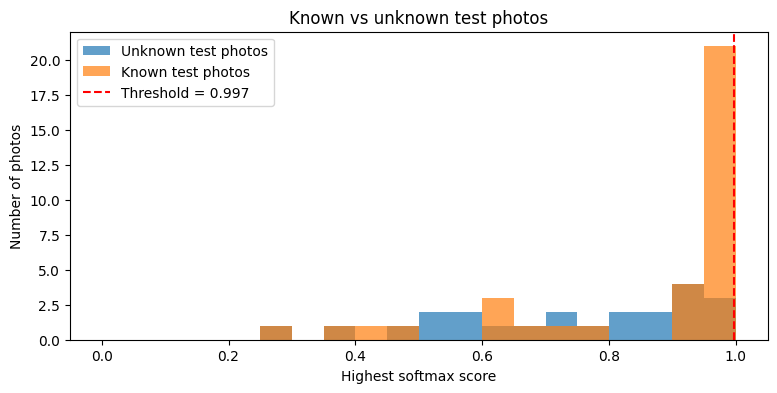

In [35]:
# Histogram: scores of known photos vs unknown photos
bins = np.linspace(0, 1, 21)

plt.figure(figsize=(9, 4))
plt.hist(test_unknown_scores, bins=bins, alpha=0.7, label="Unknown test photos")
plt.hist(test_known_scores, bins=bins, alpha=0.7, label="Known test photos")
plt.axvline(threshold, color="red", linestyle="--", label=f"Threshold = {threshold:.3f}")
plt.xlabel("Highest softmax score")
plt.ylabel("Number of photos")
plt.title("Known vs unknown test photos")
plt.legend()
plt.show()

**The histogram:** most known photos (orange) have scores above **0.95**, while the unknown photos (blue) spread from about 0.3 to 1.0. But a few unknown photos also reach **0.95–1.0**, the same range as most known photos. This is why the threshold has to sit at 0.997, at the far right. Moving it is always a **trade-off**: a lower threshold would accept more correct photos, but would also start accepting unknown ones.

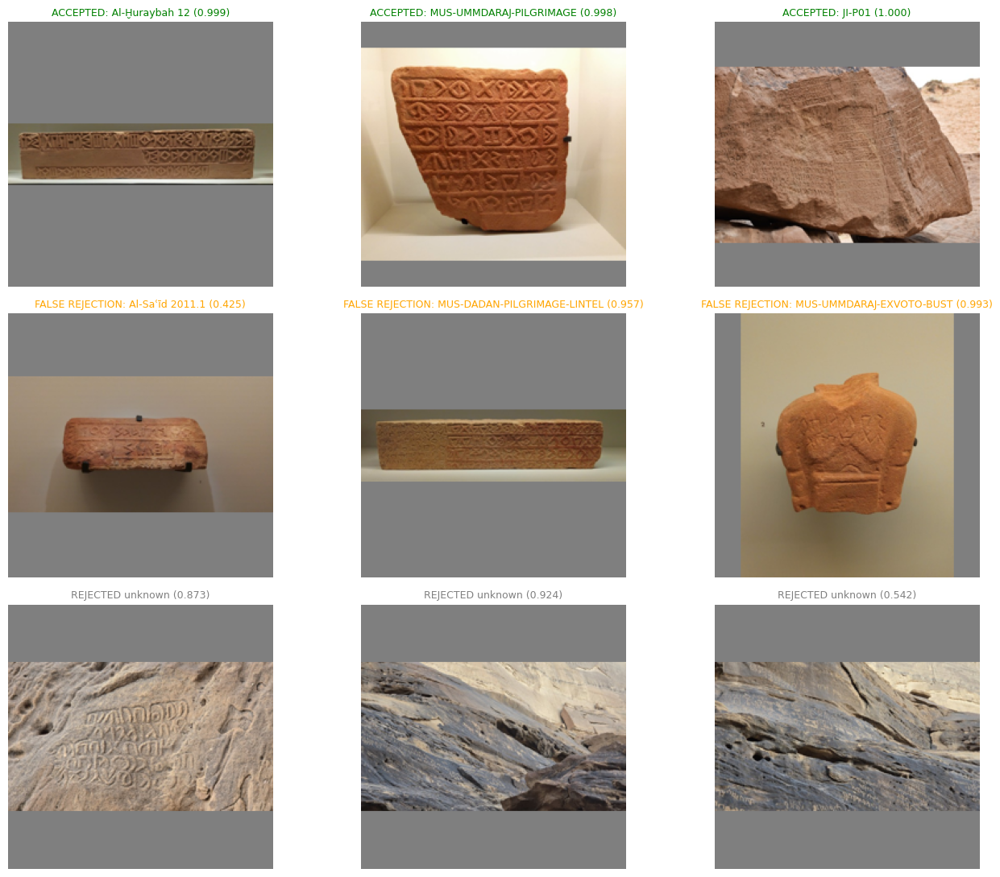

In [36]:
# Pick up to 3 examples of each case
examples = []

for i in np.where(accepted)[0][:3]:
    examples.append((X_test[i], f"ACCEPTED: {class_names[test_pred[i]]} ({test_known_scores[i]:.3f})", "green"))

for i in np.where(~accepted)[0][:3]:
    examples.append((X_test[i], f"FALSE REJECTION: {class_names[y_test[i]]} ({test_known_scores[i]:.3f})", "orange"))

for i in range(3):
    examples.append((X_test_unknown[i], f"REJECTED unknown ({test_unknown_scores[i]:.3f})", "grey"))

# Show them
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")

for i in range(len(examples)):
    image, title, color = examples[i]
    axes[i].imshow(image.astype("uint8"))
    axes[i].set_title(title, fontsize=9, color=color)

plt.tight_layout()
plt.show()

**Why we accept this trade-off**
- For a visitor, *"not recognised, try another photo"* is a much safer error than a **wrong translation** of an ancient text.
- With only 23 + 23 unknown photos and one known test photo per class, the threshold is a **rough estimate**, not a final operating point.
- More photos per inscription should make the model more confident on known inscriptions, so fewer correct photos would be rejected.

## **9. Real Inscription Recognition Demo**
The full pipeline on real photographs: **CNN → class + score → threshold → verified record**. The record lookup happens only after the CNN's decision.

In [37]:
# Recognise one photo and print its record
def recognise(path):
    # 1) The CNN gives a score for every class
    image = load_image(path)
    image = preprocess(image[None])          # add a batch dimension: (1, 224, 224, 3)
    scores = model.predict(image, verbose=0)[0]

    best = scores.argmax()
    name = class_names[best]
    confidence = scores[best]

    plt.figure(figsize=(6, 3.5))
    plt.imshow(ImageOps.exif_transpose(Image.open(path)))
    plt.axis("off")
    plt.show()
    print(f"Predicted class: {name}   |   Score: {confidence:.3f}")

    # 2) Below the threshold: do not show any reading
    if confidence < threshold:
        print("Status: NOT RECOGNISED. No reading is shown.\n")
        return

    # 3) Recognised: look up its record in the table
    print("Status: RECOGNISED")
    matches = supported[supported["class_name"] == name]
    if len(matches) == 0:
        print("No record has been added for this inscription yet.\n")
        return

    record = matches.iloc[0]
    print("Inscription     :", record["name_en"], "|", record["name_ar"])
    print("Official IDs    :", record["official_ids"] or "none")
    print("Location        :", record["site"])
    print("Script          :", record["script"])
    print("Transliteration :", record["transliteration"] or "not available")
    print("Translation     :", record["translation_en"] or "not available")
    print("الشرح بالعربية   :", record["explanation_ar"] or "لا تتوفر قراءة موثقة")
    print("Context         :", record["context_en"])
    print("Source          :", record["citation"])
    print()

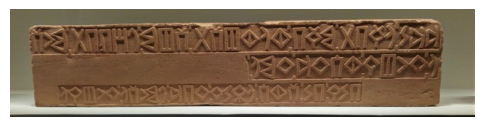

Predicted class: Al-Ḫuraybah 12   |   Score: 0.999
Status: RECOGNISED
Inscription     : Dedication lintel of Ddn (Al-Ḫuraybah 12) | ساكف نقش الإهداء «ددن» (الخريبة ١٢)
Official IDs    : OCIANA Dadanitic: Al-Ḫuraybah 12; RCU.2023.128
Location        : Dadan sanctuary (al-Khuraybah), AlUla
Script          : Dadanitic (verified: corpus + RCU)
Transliteration : ddn/hṯbt/mṯb/w hwḍʾt/ʾḍm/l- ḏġbt/mrʾ | -h/f rḍy/w s¹ʿd/ʿm -h | bny/bn/ʾws¹/h- ṣnʿ/ʿbd/l- mrʾ -h/f rḍy -h
Translation     : Ddn offered donations and hwḍʾt ʾḍm to Ḏġbt, her lord, and so may he favour and help her family [or paternal uncle or grandfather] / Bny son of ʾws¹, the artisan, made [this] for his lord and so may it satisfy him
الشرح بالعربية   : نقش إهداء من معبد دادان: قدّمت «ددن» عطايا للإله ذي غابة ودعت أن يرعى أسرتها، ويذكر السطر الأخير الحِرفي «بني بن أوس» الذي صنع القطعة.
Context         : Sandstone lintel (35 × 220 × 50 cm), 5th–1st century BCE, from the sanctuary of Dadan; excavated by King Saud University.
Source   

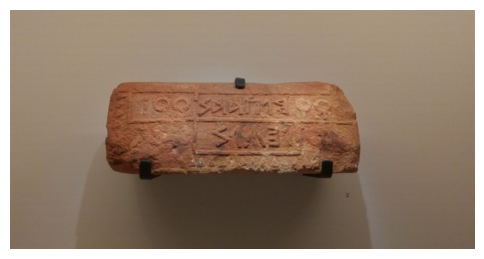

Predicted class: MUS-DADAN-PRIEST-RELIEF   |   Score: 0.425
Status: NOT RECOGNISED. No reading is shown.



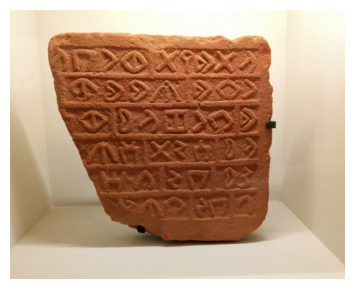

Predicted class: MUS-UMMDARAJ-PILGRIMAGE   |   Score: 0.998
Status: RECOGNISED
Inscription     : Pilgrimage of Hatadiyah and Rfd to Umm Daraj | نقش حج «هتدية» و«رفد» إلى أم درج
Official IDs    : RCU.2020.147.244
Location        : Umm Daraj sanctuary, AlUla
Script          : Dadanitic / Lihyanite (RCU)
Transliteration : not available
Translation     : Hatadiyah and her god (husband) Rfd made the pilgrimage (for Dhû Gharbay), he was pleased with them and he (made them happy). The year … (Ja)sam the son of Lûd(ân) … the son of (Lihyân).
الشرح بالعربية   : سجلّ حج من معبد أم درج الجبلي: أدّى «هتدية» وزوجها «رفد» الحج للإله ذي غابة، ويذكر آخر النص المتضرر سنةً وأسماءً مرتبطة بلحيان.
Context         : Sandstone block (32 × 32 × 28 cm), 6th–2nd century BCE, from the Umm Daraj mountain sanctuary.
Source          : RCU Collections: Dadan and Liyhan (Royal Commission for AlUla catalogue, 29 Oct 2024), RCU.2020.147.244; Wikimedia Commons (Zunkir 2020); Livius.org



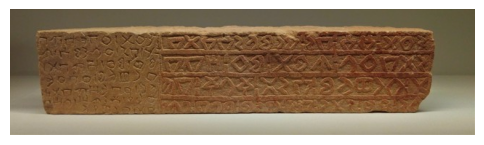

Predicted class: MUS-DADAN-PILGRIMAGE-LINTEL   |   Score: 0.957
Status: NOT RECOGNISED. No reading is shown.



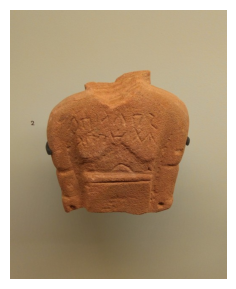

Predicted class: MUS-UMMDARAJ-EXVOTO-BUST   |   Score: 0.993
Status: NOT RECOGNISED. No reading is shown.



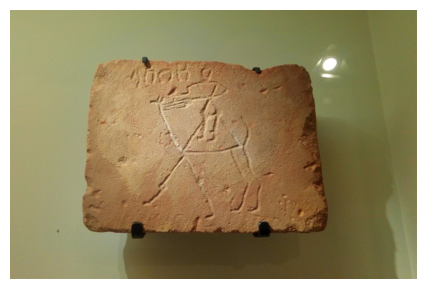

Predicted class: MUS-DADAN-PRIEST-RELIEF   |   Score: 0.992
Status: NOT RECOGNISED. No reading is shown.



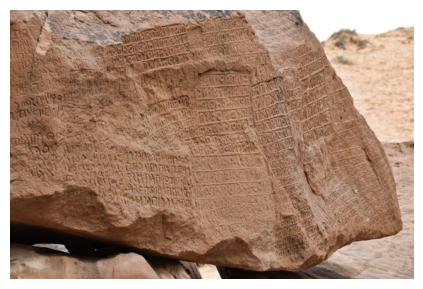

Predicted class: JI-P01   |   Score: 1.000
Status: RECOGNISED
Inscription     : Jabal ʿIkmah boulder face P01 | لوحة صخرية في جبل عكمة P01
Official IDs    : none
Location        : Jabal ʿIkmah, AlUla
Script          : Not verified for this panel (Jabal ʿIkmah has mainly Dadanitic plus other scripts)
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Rock panel at Jabal ʿIkmah, the 'open library' of AlUla with hundreds of ancient inscriptions (UNESCO Memory of the World).
Source          : Photographs: Wikimedia Commons (Richard Mortel, Z thomas)



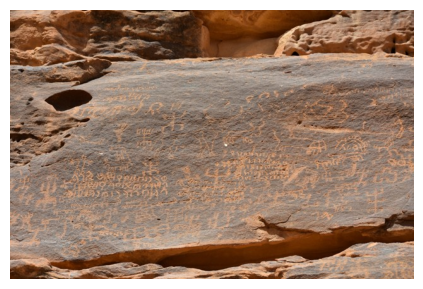

Predicted class: JI-P02   |   Score: 0.930
Status: NOT RECOGNISED. No reading is shown.



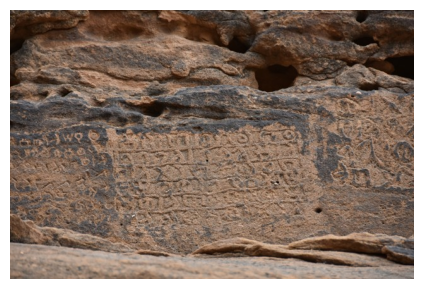

Predicted class: JI-P07   |   Score: 0.941
Status: NOT RECOGNISED. No reading is shown.



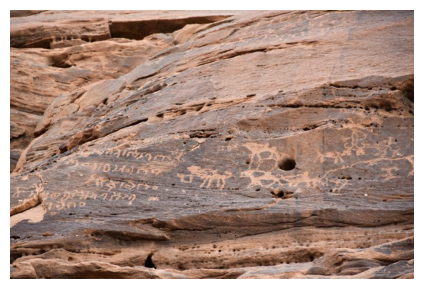

Predicted class: JI-P04   |   Score: 1.000
Status: RECOGNISED
Inscription     : Jabal ʿIkmah rock panel P04 | لوحة صخرية في جبل عكمة P04
Official IDs    : none
Location        : Jabal ʿIkmah, AlUla
Script          : Not verified for this panel (Jabal ʿIkmah has mainly Dadanitic plus other scripts)
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Rock panel at Jabal ʿIkmah, the 'open library' of AlUla with hundreds of ancient inscriptions (UNESCO Memory of the World).
Source          : Photographs: Wikimedia Commons (Richard Mortel, Z thomas)



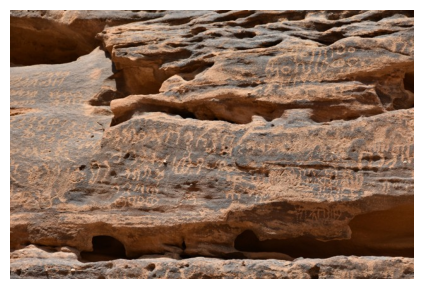

Predicted class: JI-P08   |   Score: 0.675
Status: NOT RECOGNISED. No reading is shown.



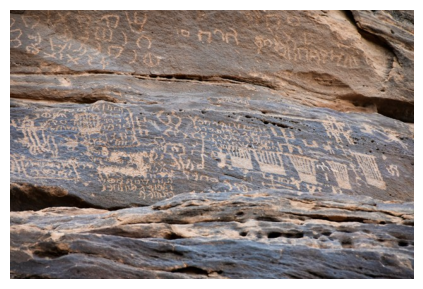

Predicted class: JI-P05   |   Score: 0.975
Status: NOT RECOGNISED. No reading is shown.



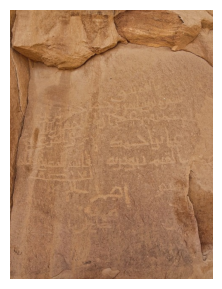

Predicted class: AU-ARABIC-06   |   Score: 0.646
Status: NOT RECOGNISED. No reading is shown.



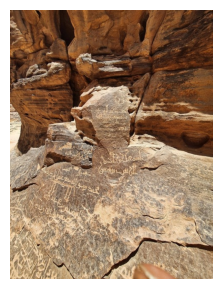

Predicted class: AU-ARABIC-02   |   Score: 1.000
Status: RECOGNISED
Inscription     : Early Islamic inscription panel at al-Ula (2) | لوحة نقوش عربية إسلامية مبكرة في العلا (2)
Official IDs    : none
Location        : AlUla
Script          : Early Islamic Arabic
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Real photographs from Wikimedia Commons (4 photos).
Source          : Wikimedia Commons (see sources.csv)



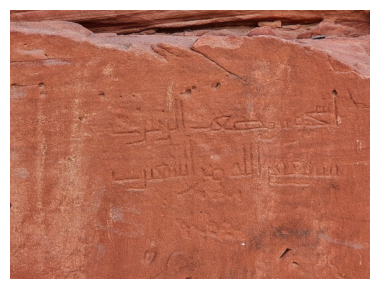

Predicted class: AU-ARABIC-03   |   Score: 0.998
Status: RECOGNISED
Inscription     : Early Islamic inscription at Dadan, al-Ula | نقش عربي إسلامي مبكر في دادان، العلا
Official IDs    : none
Location        : Dadan, AlUla
Script          : Early Islamic Arabic
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Real photographs from Wikimedia Commons (2 photos).
Source          : Wikimedia Commons (see sources.csv)



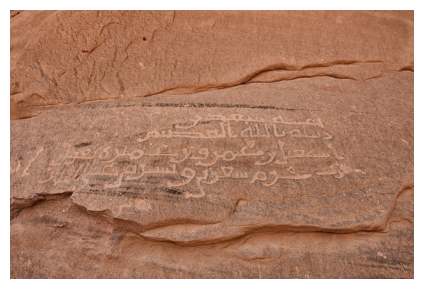

Predicted class: AU-ARABIC-04   |   Score: 0.945
Status: NOT RECOGNISED. No reading is shown.



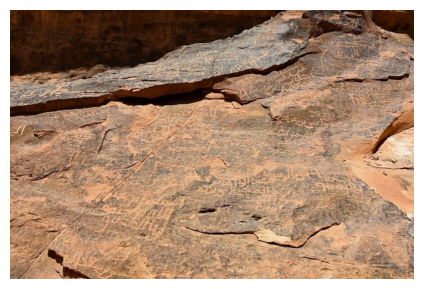

Predicted class: AU-ARABIC-02   |   Score: 0.997
Status: NOT RECOGNISED. No reading is shown.



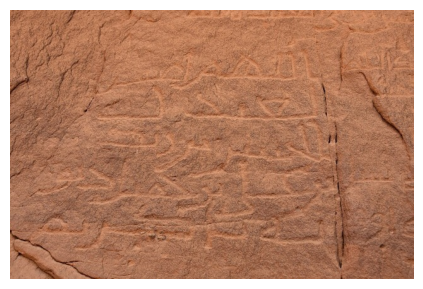

Predicted class: AU-ARABIC-01   |   Score: 0.960
Status: NOT RECOGNISED. No reading is shown.



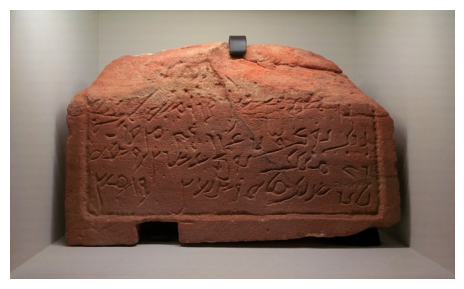

Predicted class: AU-NABARAB-01   |   Score: 0.993
Status: NOT RECOGNISED. No reading is shown.



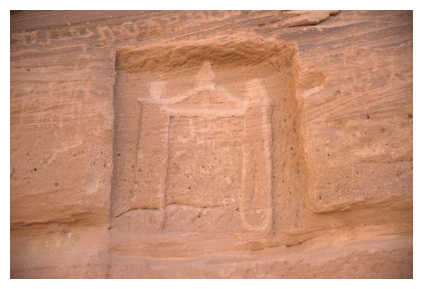

Predicted class: HG-ITHLIB-01   |   Score: 0.998
Status: RECOGNISED
Inscription     : Betyl niche with ancient (Nabataean) inscriptions, Jabal Ithlib | مشكاة نبطية مع نقوش، جبل إثلب، الحِجر
Official IDs    : none
Location        : Jabal Ithlib, Hegra (Mada'in Salih)
Script          : Nabataean
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Real photographs from Wikimedia Commons (3 photos).
Source          : Wikimedia Commons (see sources.csv)



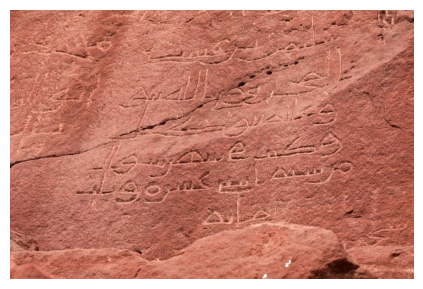

Predicted class: JI-P01   |   Score: 0.715
Status: NOT RECOGNISED. No reading is shown.



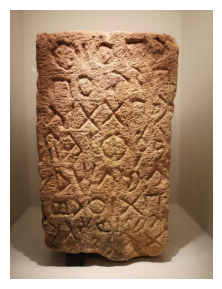

Predicted class: AU-MINAIC-01   |   Score: 1.000
Status: RECOGNISED
Inscription     : Minaic inscribed stela from al-ʿUla | مسلّة بالخط المعيني من العلا
Official IDs    : none
Location        : AlUla
Script          : Minaic (Ancient South Arabian)
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Inscribed stela in Minaic, al-ʿUla, 6th–2nd century BCE, red sandstone (Institut du monde arabe exhibition).
Source          : Wikimedia Commons; Flickr (Carole Raddato)



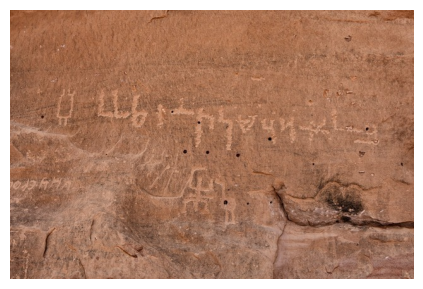

Predicted class: AU-ROCKART-01   |   Score: 0.995
Status: NOT RECOGNISED. No reading is shown.



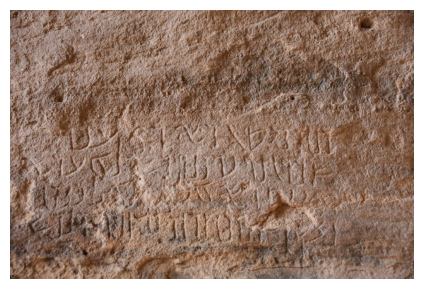

Predicted class: HG-ITHLIB-02   |   Score: 0.937
Status: NOT RECOGNISED. No reading is shown.



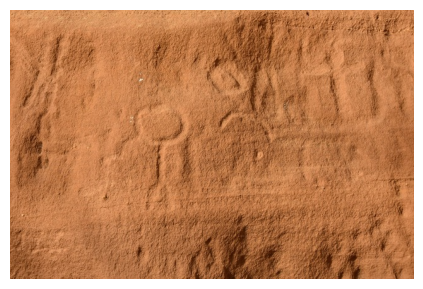

Predicted class: HG-ITHLIB-03   |   Score: 0.634
Status: NOT RECOGNISED. No reading is shown.



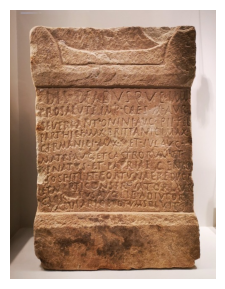

Predicted class: HG-LATIN-01   |   Score: 0.999
Status: RECOGNISED
Inscription     : Latin dedication for Caracalla and Julia Domna | إهداء لاتيني لسلامة الإمبراطور كاراكلا وجوليا دومنا
Official IDs    : none
Location        : Hegra Roman fort, AlUla
Script          : Latin
Transliteration : not available
Translation     : Dedication for the salvation of the emperor Caracalla and Julia Domna (AD 213–217).
الشرح بالعربية   : نقش لاتيني من الحصن الروماني في الحِجر، يهدي البناء لسلامة الإمبراطور كاراكلا وأمه جوليا دومنا (213–217م).
Context         : 
Source          : Flickr (Carole Raddato); Livius.org (J. Lendering)



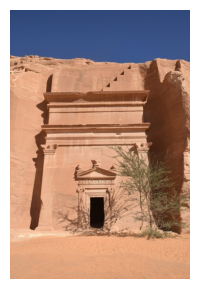

Predicted class: HG-T021   |   Score: 0.999
Status: RECOGNISED
Inscription     : Hegra tomb 21 (Qasr al-Bint) | قبر رقم 21 في الحِجر (قصر البنت)
Official IDs    : none
Location        : Hegra (al-Ḥijr / Madāʾin Ṣāliḥ), AlUla
Script          : Nabataean
Transliteration : not available
Translation     : not available
الشرح بالعربية   : لا تتوفر قراءة موثقة
Context         : Inscription above the door: tomb carved by the masons Aftah son of ʿAbdʿobodat, Wahbu son of Afsa and Huru for Arus son of Farwan (a prefect) and his family.
Source          : photo description on Wikimedia Commons (Following Hadrian / C. Raddato), not a scholarly edition



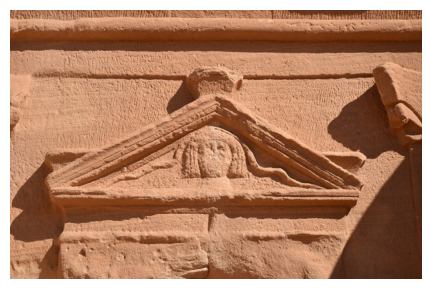

Predicted class: HG-T044   |   Score: 0.267
Status: NOT RECOGNISED. No reading is shown.



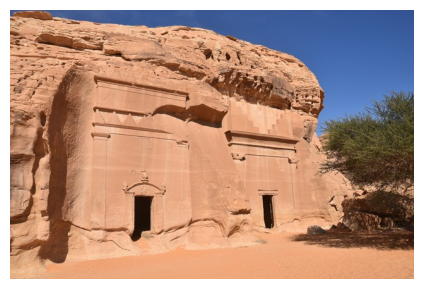

Predicted class: HG-T039   |   Score: 0.773
Status: NOT RECOGNISED. No reading is shown.



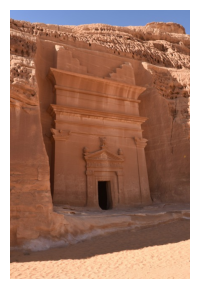

Predicted class: HG-T044   |   Score: 0.983
Status: NOT RECOGNISED. No reading is shown.



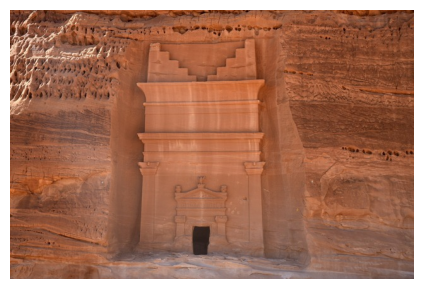

Predicted class: HG-T110   |   Score: 0.366
Status: NOT RECOGNISED. No reading is shown.



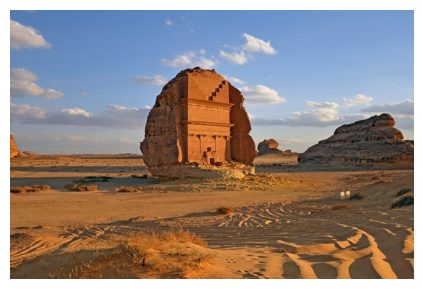

Predicted class: HG-T110   |   Score: 0.994
Status: NOT RECOGNISED. No reading is shown.



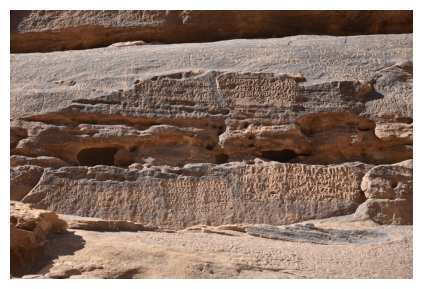

Predicted class: JI-P07   |   Score: 0.645
Status: NOT RECOGNISED. No reading is shown.



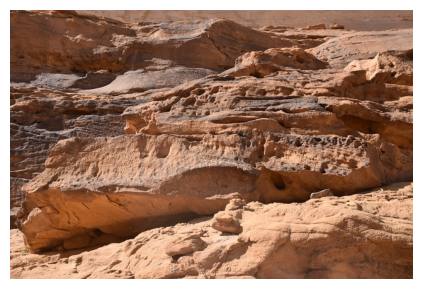

Predicted class: JI-P09   |   Score: 0.995
Status: NOT RECOGNISED. No reading is shown.



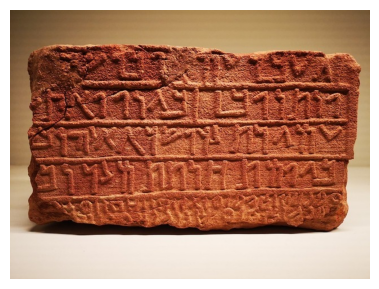

Predicted class: MUS-BILINGUAL-DADANITIC-ARAMAIC   |   Score: 0.492
Status: NOT RECOGNISED. No reading is shown.



In [38]:
# Run NAQSH AI on the test photo of every inscription
for path in test_known["image_path"]:
    recognise(path)

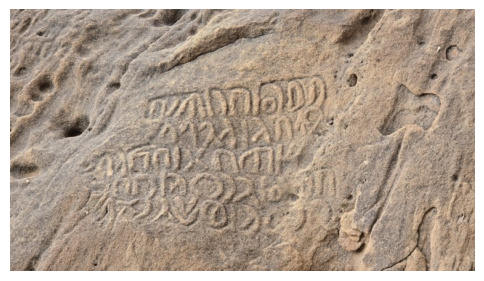

Predicted class: JI-P01   |   Score: 0.873
Status: NOT RECOGNISED. No reading is shown.



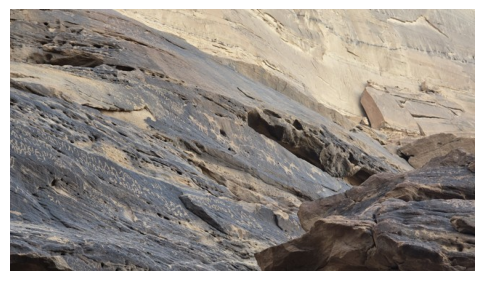

Predicted class: JI-P04   |   Score: 0.924
Status: NOT RECOGNISED. No reading is shown.



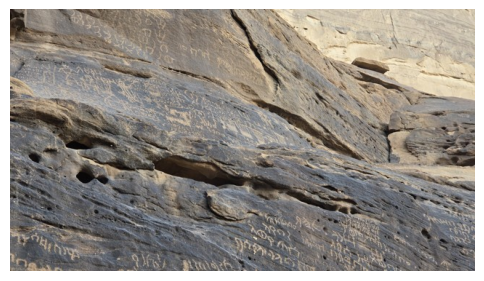

Predicted class: JI-P04   |   Score: 0.542
Status: NOT RECOGNISED. No reading is shown.



In [39]:
# Run NAQSH AI on 3 photos of inscriptions it does not know
for path in test_unknown["image_path"].head(3):
    recognise(path)

**Unknown inscriptions:** the 3 photos got scores between 0.54 and 0.92, all below the threshold, so they were **rejected**, and no reading was shown. A plain classifier without a threshold would have called them JI-P01 or JI-P04.

## **10. Conclusion**

In [40]:
# Save the final results of this run
summary = {
    "photos_total": len(images),
    "classes": len(class_names),
    "train_photos": len(X_train),
    "val_photos": len(X_val),
    "test_photos": len(X_test),
    "val_unknown_photos": len(X_val_unknown),
    "test_unknown_photos": len(X_test_unknown),
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_macro_f1": f1_score(y_test, test_pred, average="macro"),
    "swapped_split_accuracy": n_swap_correct / len(y_swap_test),
    "threshold": threshold,
    "known_test_accepted_correct": correctly_accepted,
    "known_test_false_rejections": false_rejections,
    "unknown_test_rejected": unknown_rejected,
    "unknown_test_false_acceptances": unknown_accepted,
}

# numpy numbers -> normal Python numbers, so json can save them
for key in summary:
    summary[key] = summary[key].item() if hasattr(summary[key], "item") else summary[key]

with open("models/evaluation_results.json", "w") as f:
    json.dump(summary, f, indent=2)

pd.Series(summary)

photos_total                      181.000000
classes                            35.000000
train_photos                       98.000000
val_photos                          2.000000
test_photos                        35.000000
val_unknown_photos                 23.000000
test_unknown_photos                23.000000
test_accuracy                       0.742857
test_macro_f1                       0.685714
swapped_split_accuracy              0.800000
threshold                           0.997002
known_test_accepted_correct        10.000000
known_test_false_rejections        25.000000
unknown_test_rejected              23.000000
unknown_test_false_acceptances      0.000000
dtype: float64

**What was developed**
- A dataset of **181 real AlUla photographs**: **35 supported inscriptions** (135 photos, 2–15 per inscription) and **46 unknown photos** for rejection tests, with every photo's source, author and licence documented.
- The project now covers **several scripts**: Dadanitic, Nabataean, Minaic, Latin, Nabataeo-Arabic and early Islamic Arabic, from Dadan, Umm Daraj, Jabal ʿIkmah, Hegra and other sites in AlUla.
- Records for the supported inscriptions, backed by a knowledge base of **1,657 documented inscriptions**.
- A **MobileNetV2** model trained with transfer learning and fine-tuning, a confidence threshold that rejects unknown photos, and a demo that shows the record of each recognised photo.

**Model performance** (independent test photos)

| Measure | Result |
|---|---|
| Test accuracy | **26 / 35 = 74.3 %** |
| Test macro-F1 | 0.686 |
| Second check (swapped photos) | **28 / 35 = 80.0 %** |
| Both runs together | 54 / 70 = 77 % |
| Threshold | 0.997 |
| Known photos accepted (all correct) | 10 / 35 |
| Wrong readings shown | **0** |
| Unknown photos rejected | **23 / 23** |

**Limitations**
- Most inscriptions have only **1–3 training photos**, and the test set has **one photo per inscription**, so every result can change by a few photos.
- The 9 mistakes are between **similar-looking inscriptions** (Arabic panels, Hegra tombs, Jabal ʿIkmah panels).
- The threshold is very strict, so **25 of 35 known photos were rejected**, 16 of them correctly classified.
- Validation has only **2 known photos**, so early stopping is a weak signal.
- One possible near-duplicate pair crosses train and test (**IMG-076 / IMG-078**, AU-ARABIC-02).
- 2 photos (IMG-092, IMG-152) have **non-commercial licences** (CC BY-NC); fine for a student project, but not for a commercial app.
- **Not tested on real visitor photos**, and no reading exists yet for the Jabal ʿIkmah panels. This is a proof of concept, not a finished product.
- It does **not** read unseen inscriptions (no OCR).

**Future improvements**
- Photograph each supported inscription **10+ times** on site (different angles, distances, light and phones), starting with the confused groups: the Arabic panels, the Hegra tombs and the Jabal ʿIkmah panels.
- Collect **real visitor photos** as an independent test set.
- With more photos, try metric learning (triplet loss) so new inscriptions can be added without retraining, and calibrate the confidence scores so the threshold can be lower.